# Task 01 — Graph-based AML triage on a synthetic transaction network

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [IBM Transactions for Anti-Money Laundering (AML)](https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml) (the `HI-Small` split)
**Task family:** graph analytics / network-aware ML · **Companion task:** `02_card_fraud_tabular.ipynb` (the traditional-ML counterpart)

---

## The task card

> **Board question.** *Our AML analysts can investigate roughly 200 accounts a week by hand. Can a graph-aware model put the right accounts at the top of that queue, how much better is it than the rules we already run, and what does it cost us to operate?*

**Business context.** A Maltese payment institution or iGaming operator sits under MFSA / MGA supervision and must monitor for money laundering. Transaction monitoring is a batch job: every night, the day's transfers are scored and a prioritised queue lands on the analysts' desk in the morning (Session 01's *batch prediction* pattern, with *human-in-the-loop* review). Laundering is rare (about 0.1 % of transfers here) and it is **structural**: a single transfer rarely looks wrong; the pattern across many accounts does: fan-out, fan-in, cycles, gather-scatter. That is why this task is about graphs.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **account-level triage model**, packaged and reproducible, with an honest temporal evaluation;
2. a short **analyst-facing explanation** of why each top-ranked account was flagged (the motif it sits in);
3. the **operational wrapper** the unit teaches: package, tests, CI gate, registered model, model card, monitoring plan;
4. a one-page **stakeholder recommendation**: what to deploy, what it costs, what it does not catch.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Batch scoring in a regulated estate; where the model plugs into the case-management tool; AI Act classification of an AML system |
| 2 · MLOps | Reproducible pipeline, quality gate on precision@k, registry + model card, drift when a new week of data arrives |
| 3 · Semantic layer | Accounts, entities and banks are already a graph, a natural seed for a knowledge graph (Session 07/08) |
| 4 · LLM/RAG | Generating the investigator's narrative for a flagged account from its ego-network (Session 10) |

**Assessment.** This notebook is a *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The data is **synthetic** (generated by IBM's AML simulator, Altman et al., NeurIPS 2023 datasets track). It has realistic *shapes* (banks, currencies, payment formats, laundering typologies) and some unrealistic artefacts, listed in the dataset card below. Treat it as a sandbox for method, not as evidence about real laundering.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–3 | Dataset card, first look, the injected typologies | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 4–9 | Account graph, motif signals, the row-level control, the account model, reading the result, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 10–12 | The module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. |

**What you need from Parts A and B**

- **Code to package:** `get_raw` and `load_transactions` (Section 1); the graph build and structural signals (Sections 4–5); `fit_eval` and `motif` (Section 7); `account_table` and `fit_score` for the forward evaluation (Section 9). Section 6's row-level model is a control experiment: keep its result as evidence, not as a service.
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 515,070 accounts with 19 profile and 12 structural features; 154,521 held-out accounts, 1,759 of them laundering; AUPRC 0.292 and a top-200 queue with 198 true laundering accounts; forward in time (Trap 1), 372,954 accounts in days 6–10, 3,357 laundering, AUPRC 0.247.
- **Runtime:** about 7 minutes and 3.5 GB of RAM on a laptop (about 420 s on the build machine).

In [1]:
import time; T_START = time.time()

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

Everything is parameterised at the top. `WINDOW_END` lets you shrink the data on a small laptop (but see the dataset card: laundering patterns span 3–4 days, so windows shorter than a week cut most of them in half).

In [2]:
import os, re, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import scipy.sparse as sp
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.csv as pc

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "ealtman2019/ibm-transactions-for-anti-money-laundering-aml"
FILES = ["HI-Small_Trans.csv", "HI-Small_Patterns.txt", "HI-Small_accounts.csv"]
WINDOW_START = pd.Timestamp("2022-09-01")
WINDOW_END = pd.Timestamp("2022-09-11")   # exclusive; see dataset card for why the tail is dropped
TRAIN_END = pd.Timestamp("2022-09-08")    # temporal split for transaction-level demo (train < TRAIN_END)
FORWARD_SPLIT = pd.Timestamp("2022-09-06")   # Trap 1: learn on days 1-5, score days 6-10
ANALYST_CAPACITY = 200                    # accounts the team can investigate per review cycle
RUN_LOUVAIN = True                        # community detection on ~420k nodes takes 1-3 min; set False on a slow laptop

# data lives outside the repo tree that gets committed (data/ is git-ignored)
DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

# ---- chart style (one system for the whole notebook) ------------------------
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # categorical slots, fixed order
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
print(f"pandas {pd.__version__} · networkx {nx.__version__} · numpy {np.__version__}")

pandas 3.1.0 · networkx 3.7 · numpy 2.5.4


# Part A — Explore the data

*Sections 1–3: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw` and `load_transactions`.*

| Field | Value |
|---|---|
| **Source** | Kaggle: `ealtman2019/ibm-transactions-for-anti-money-laundering-aml` (IBM Research) |
| **Licence** | CDLA-Sharing-1.0: free to use and share for teaching; derived data must carry the same licence |
| **Provenance** | Synthetic. Generated by IBM's AML simulator (Altman, Blanuša, von Niederhäusern, Egressy, Anghel, Atasu: *Realistic Synthetic Financial Transactions for Anti-Money Laundering Models*, NeurIPS 2023 D&B track). Six splits: `{HI,LI}-{Small,Medium,Large}`; HI = higher illicit ratio |
| **Split used** | `HI-Small`: 5.08 M transactions, 515 k accounts, 30.5 k bank identifiers, 18 days (1–18 Sep 2022); 5,177 laundering transactions (0.10 %; 4,522 of them in the 10-day window we keep); 5,862 laundering accounts (1.1 % of accounts) |
| **Files** | `HI-Small_Trans.csv` (476 MB): one row per transfer. `HI-Small_Patterns.txt`: the 234 injected laundering *attempts* with their typology (FAN-OUT, FAN-IN, GATHER-SCATTER, CYCLE, RANDOM). `HI-Small_accounts.csv`: account → bank, entity id, entity name |
| **Schema (Trans)** | `Timestamp`, `From Bank`, `Account` (sender), `To Bank`, `Account` (receiver), `Amount Received`, `Receiving Currency`, `Amount Paid`, `Payment Currency`, `Payment Format`, `Is Laundering` |
| **Label** | `Is Laundering` per transaction. We derive an **account label**: involved in ≥ 1 laundering transaction in the window |
| **PII** | None: account ids and entity names are synthetic |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **The tail is laundering-only.** Normal traffic stops on 10 Sep; days 11–18 contain 1,108 transactions of which 655 are laundering. A model evaluated on the tail looks brilliant and is lying. We cut at `WINDOW_END = 2022-09-11` (Trap 3).
2. **Day 1 is a burst.** 1 Sep has 1.1 M transfers (account initialisation, lots of `Reinvestment` self-transfers). Degree features computed on day 1 are inflated.
3. ⚠ **Self-transfers.** ~11 % of rows have sender = receiver (`Reinvestment`, some `Cheque`). They are not edges in the account graph; they are kept as account activity (Trap 4).
4. ⚠ **Fifteen currencies, no FX table.** Amounts are in the payment currency. We apply a fixed September-2022 approximation to USD (`FX` below). This is an assumption: Trap 2 measures how much it matters.
5. **Patterns span days.** Median laundering attempt lasts 72–85 h (GATHER-SCATTER ~150 h). Any window shorter than the full 10 days truncates most attempts.
6. **Only the patterned attempts are typed.** 1,854 of the 5,177 laundering transactions belong to a typed attempt; the rest are untyped laundering.

In [3]:
def get_raw(filename: str) -> Path:
    '''Return a local path to a raw file, downloading from Kaggle on first use.
    Kaggle credentials: set KAGGLE_API_TOKEN (access token) or place kaggle.json in ~/.kaggle/.
    '''
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    path = Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))
    return path

def load_transactions() -> pd.DataFrame:
    '''Load HI-Small_Trans.csv into a compact frame (categoricals via Arrow dictionary encoding), cached as parquet.'''
    cache = PROCESSED / "aml_hi_small.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    t = time.time()
    convert = pc.ConvertOptions(column_types={"From Bank": pa.string(), "To Bank": pa.string()}, auto_dict_encode=True)
    df = pc.read_csv(get_raw("HI-Small_Trans.csv"), convert_options=convert).to_pandas()
    df.columns = ["ts", "from_bank", "from_acct", "to_bank", "to_acct", "amt_recv", "recv_cur",
                  "amt_paid", "pay_cur", "fmt", "is_laundering"]
    df["ts"] = pd.to_datetime(df["ts"].astype(str), format="%Y/%m/%d %H:%M")
    for c in ["from_bank", "from_acct", "to_bank", "to_acct"]:
        df[c] = df[c].astype(str)
    df.to_parquet(cache)
    print(f"loaded + cached in {time.time()-t:.1f}s")
    return df

t0 = time.time()
tx = load_transactions()
tx = tx[(tx.ts >= WINDOW_START) & (tx.ts < WINDOW_END)].reset_index(drop=True)
print(f"{len(tx):,} transactions in window · {time.time()-t0:.1f}s · {tx.memory_usage(deep=True).sum()/1e6:.0f} MB")
tx.head()

5,077,237 transactions in window · 1.3s · 493 MB


,ts,from_bank,from_acct,to_bank,to_acct,amt_recv,recv_cur,amt_paid,pay_cur,fmt,is_laundering
0,2022-09-01 00:20:00,010,8000EBD30,010,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022-09-01 00:20:00,03208,8000F4580,001,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022-09-01 00:00:00,03209,8000F4670,03209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022-09-01 00:02:00,012,8000F5030,012,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022-09-01 00:06:00,010,8000F5200,010,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0


In [4]:
# Fixed FX approximation to USD (September 2022). An assumption, not a fact: Trap 2 measures what it moves.
FX = {"US Dollar": 1.0, "Euro": 1.0, "UK Pound": 1.15, "Swiss Franc": 1.03, "Canadian Dollar": 0.76,
      "Australian Dollar": 0.68, "Yen": 0.0070, "Yuan": 0.145, "Rupee": 0.0125, "Shekel": 0.29,
      "Saudi Riyal": 0.27, "Mexican Peso": 0.050, "Brazil Real": 0.19, "Ruble": 0.0165, "Bitcoin": 20000.0}
assert set(tx.pay_cur.astype(str).unique()) <= set(FX), "unmapped currency"
tx["amt_usd"] = tx.amt_paid * tx.pay_cur.astype(str).map(FX)
tx["day"] = tx.ts.dt.floor("D")
tx["is_self"] = tx.from_acct == tx.to_acct

n_acc = pd.concat([tx.from_acct, tx.to_acct]).nunique()
print(f"accounts: {n_acc:,} · banks: {pd.concat([tx.from_bank, tx.to_bank]).nunique()} · "
      f"laundering tx: {tx.is_laundering.sum():,} ({tx.is_laundering.mean():.2%}) · self-transfers: {tx.is_self.mean():.1%}")

accounts: 515,070 · banks: 30528 · laundering tx: 4,522 (0.09%) · self-transfers: 11.6%


## 2 · First look

*Part A · Explore · read.*

Two things to see before touching a graph: the shape of the traffic over time (and why the window is cut where it is), and that laundering is spread across payment formats rather than hiding in one.

,n,laundering,rate
ts,,,
2022-09-08,482773,539,0.001116
2022-09-09,654467,514,0.000785
2022-09-10,208325,442,0.002122
2022-09-11,396,232,0.585859
2022-09-12,281,170,0.604982
2022-09-13,184,106,0.576087


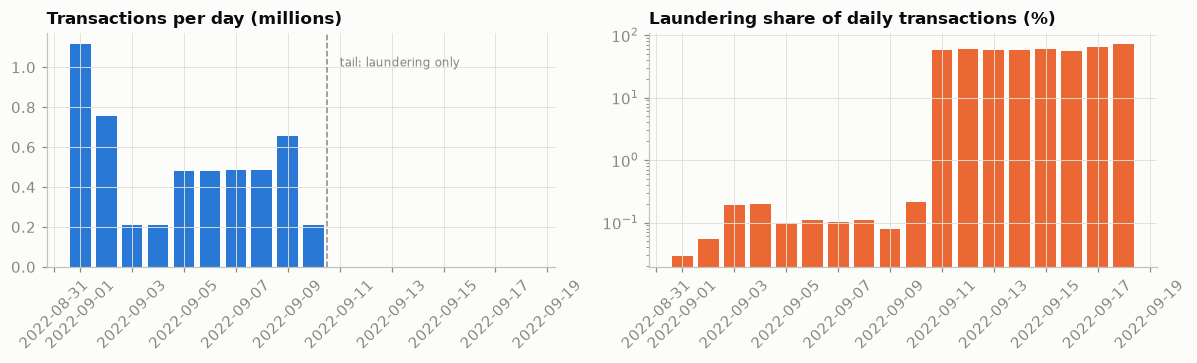

In [5]:
full = load_transactions()
daily = full.groupby(full.ts.dt.floor("D")).agg(n=("ts", "size"), laundering=("is_laundering", "sum"))
daily["rate"] = daily.laundering / daily.n

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
ax.bar(daily.index, daily.n / 1e6, color=SERIES[0], width=0.8)
ax.axvline(WINDOW_END - pd.Timedelta(hours=12), color=MUTED, ls="--", lw=1)
ax.set_title("Transactions per day (millions)"); ax.set_ylabel("")
ax.text(WINDOW_END, daily.n.max() / 1e6 * 0.9, "tail: laundering only", color=MUTED, fontsize=8)
ax = axes[1]
ax.bar(daily.index, daily.rate * 100, color=SERIES[1], width=0.8)
ax.set_title("Laundering share of daily transactions (%)")
ax.set_yscale("log")
for a in axes:
    a.tick_params(axis="x", rotation=45)
plt.tight_layout()
del full                                  # the full 18 days are not needed again (frees about 0.8 GB)
daily.loc["2022-09-08":"2022-09-13"]

In [6]:
fmt_tab = (tx.groupby(tx.fmt.astype(str))
             .agg(n=("ts", "size"), laundering=("is_laundering", "sum"), usd_median=("amt_usd", "median"))
             .assign(rate=lambda d: d.laundering / d.n).sort_values("n", ascending=False))
fmt_tab.style.format({"n": "{:,}", "laundering": "{:,}", "usd_median": "{:,.0f}", "rate": "{:.3%}"})

,n,laundering,usd_median,rate
fmt,,,,
Cheque,"1,864,331",324,"1,045",0.017%
Credit Card,"1,323,324",206,580,0.016%
ACH,"599,689","3,828","1,072",0.638%
Cash,"490,891",108,851,0.022%
Reinvestment,"481,056",0,"1,054",0.000%
Wire,"171,855",0,474,0.000%
Bitcoin,"146,091",56,"1,398",0.038%


## 3 · What laundering looks like here: the injected typologies

*Part A · Explore · read; these typed attempts become your test cases (C4).*

`HI-Small_Patterns.txt` lists every injected laundering *attempt* with its typology. This is the ground truth a real bank never has, which makes it ideal for learning what each motif looks like in a graph before trying to detect it blind.

In [7]:
def load_patterns() -> pd.DataFrame:
    rows, cur, attempt = [], None, -1
    for line in open(get_raw("HI-Small_Patterns.txt")):
        m = re.match(r"BEGIN LAUNDERING ATTEMPT - ([A-Z\- ]+?):", line)
        if m:
            cur, attempt = m.group(1).strip(), attempt + 1
            continue
        if line.startswith("END"):
            cur = None
            continue
        if cur and line.strip():
            p = line.strip().split(",")
            rows.append((attempt, cur, p[0], p[1], p[2], p[3], p[4], float(p[7]), p[8], p[9]))
    pt = pd.DataFrame(rows, columns=["attempt", "pattern", "ts", "from_bank", "from_acct", "to_bank", "to_acct",
                                     "amt_paid", "pay_cur", "fmt"])
    pt["ts"] = pd.to_datetime(pt.ts, format="%Y/%m/%d %H:%M")
    return pt

patterns = load_patterns()
attempts = (patterns.groupby(["attempt", "pattern"])
            .agg(start=("ts", "min"), end=("ts", "max"), n_tx=("ts", "size"),
                 n_accounts=("from_acct", lambda s: len(set(s) | set(patterns.loc[s.index, "to_acct"]))))
            .reset_index())
attempts["hours"] = (attempts.end - attempts.start).dt.total_seconds() / 3600
summary = attempts.groupby("pattern").agg(attempts=("attempt", "size"), median_tx=("n_tx", "median"),
                                          median_accounts=("n_accounts", "median"), median_hours=("hours", "median"))
summary

,attempts,median_tx,median_accounts,median_hours
pattern,,,,
CYCLE,54,4.0,4.0,71.883333
FAN-IN,40,8.0,9.0,84.933333
FAN-OUT,48,7.0,8.0,76.658333
GATHER-SCATTER,51,14.0,15.0,150.816667
RANDOM,41,3.0,4.0,46.000000


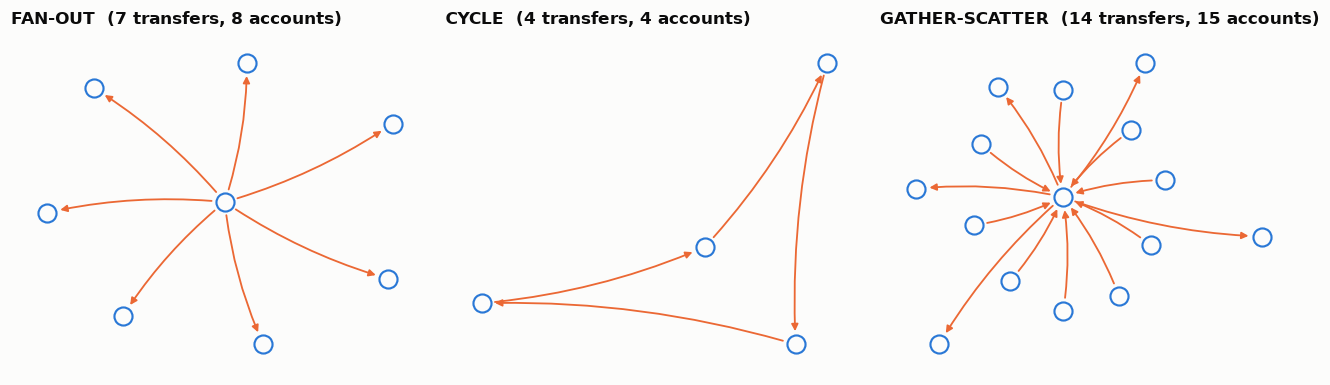

In [8]:
def draw_attempt(ax, attempt_id, title):
    sub = patterns[patterns.attempt == attempt_id]
    g = nx.DiGraph()
    for r in sub.itertuples():
        g.add_edge(r.from_acct[-4:], r.to_acct[-4:])
    pos = nx.spring_layout(g, seed=SEED, k=0.9)
    nx.draw_networkx_nodes(g, pos, ax=ax, node_size=140, node_color="#fcfcfb", edgecolors=SERIES[0], linewidths=1.4)
    nx.draw_networkx_edges(g, pos, ax=ax, edge_color=SERIES[1], arrows=True, arrowsize=9, width=1.2,
                           connectionstyle="arc3,rad=0.08")
    ax.set_title(f"{title}  ({len(sub)} transfers, {g.number_of_nodes()} accounts)"); ax.axis("off")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, pat in zip(axes, ["FAN-OUT", "CYCLE", "GATHER-SCATTER"]):
    a = attempts[attempts.pattern == pat].sort_values("n_tx").iloc[len(attempts[attempts.pattern == pat]) // 2]
    draw_attempt(ax, a.attempt, pat)
plt.tight_layout()

Three different structures, one label. A fan-out is a hub with many out-edges in a short time; a cycle returns money to where it started; gather-scatter funnels money through an intermediary and out again. None of these is visible from a single row of the transactions table, which is the whole argument for the graph.

# Part B — The given model

*Sections 4–9: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 4 · Build the account graph

*Part B · Given model · package unchanged.*

Nodes are accounts; a directed edge means *at least one transfer* from sender to receiver in the window, with edge attributes for count and total USD. Self-transfers are kept in the table for account activity but are not graph edges.

graph: 422,648 nodes · 647,316 edges · built in 10.0s


weakly connected components: 21,817 · largest 371,917 (88% of nodes) · next [24, 23, 12]


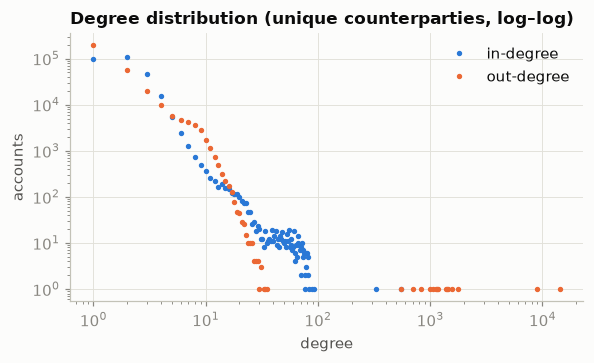

In [9]:
t0 = time.time()
edges = (tx[~tx.is_self]
         .groupby(["from_acct", "to_acct"], observed=True)
         .agg(n_tx=("ts", "size"), usd=("amt_usd", "sum"), first_ts=("ts", "min"), last_ts=("ts", "max"))
         .reset_index())
G = nx.DiGraph()
G.add_edges_from(((r.from_acct, r.to_acct, {"n_tx": r.n_tx, "usd": r.usd}) for r in edges.itertuples(index=False)))
nodes = list(G.nodes())
print(f"graph: {G.number_of_nodes():,} nodes · {G.number_of_edges():,} edges · built in {time.time()-t0:.1f}s")

wcc_sizes = sorted((len(c) for c in nx.weakly_connected_components(G)), reverse=True)
print(f"weakly connected components: {len(wcc_sizes):,} · largest {wcc_sizes[0]:,} ({wcc_sizes[0]/G.number_of_nodes():.0%} of nodes) · "
      f"next {wcc_sizes[1:4]}")

deg = pd.DataFrame({"in": dict(G.in_degree()), "out": dict(G.out_degree())})
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for col, color in zip(["in", "out"], SERIES[:2]):
    vc = deg[col].value_counts().sort_index()
    vc = vc[vc.index > 0]
    ax.plot(vc.index, vc.values, ".", ms=5, color=color, label=f"{col}-degree")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Degree distribution (unique counterparties, log–log)"); ax.set_xlabel("degree"); ax.set_ylabel("accounts")
ax.legend(); plt.tight_layout()

A heavy tail on both sides: a handful of accounts transact with thousands of counterparties (businesses, exchanges), most accounts with one or two. Anything that flags "high degree" alone will drown analysts in legitimate hubs: the motif has to be more specific than *busy*.

## 5 · Motif detection: do the typologies leave a structural fingerprint?

*Part B · Given model · package unchanged; C4 tests these signals.*

We compute four cheap structural signals and measure their **lift** against the account label: *precision of the rule* ÷ *base rate of laundering accounts* (1.14 %). Everything here is computed with sparse linear algebra or a `groupby`; no model yet.

- **2-cycle**: A→B and B→A exist (`A ∘ Aᵀ`).
- **3-cycle**: A→B→C→A (`(A²) ∘ Aᵀ`, row sums).
- **Daily fan-out / fan-in**: number of *distinct* receivers (senders) an account deals with in one day.
- **Gather-scatter**: an account whose daily fan-in and daily fan-out are both high within two consecutive days.

In [10]:
t0 = time.time()
laundering_accounts = set(tx.loc[tx.is_laundering == 1, "from_acct"]) | set(tx.loc[tx.is_laundering == 1, "to_acct"])
base_rate = len(laundering_accounts) / n_acc

A = nx.to_scipy_sparse_array(G, nodelist=nodes, format="csr", weight=None)
two_cycle = np.asarray(A.multiply(A.T).sum(axis=1)).ravel()
three_cycle = np.asarray((A @ A).multiply(A.T).sum(axis=1)).ravel()
struct = pd.DataFrame({"two_cycle": two_cycle, "three_cycle": three_cycle}, index=pd.Index(nodes, name="acct"))

fan_out_day = tx[~tx.is_self].groupby(["from_acct", "day"], observed=True).to_acct.nunique()
fan_in_day = tx[~tx.is_self].groupby(["to_acct", "day"], observed=True).from_acct.nunique()
struct["max_fan_out_day"] = fan_out_day.groupby(level=0).max().reindex(nodes).fillna(0).values
struct["max_fan_in_day"] = fan_in_day.groupby(level=0).max().reindex(nodes).fillna(0).values

# gather-scatter: fan-in >= k on day d and fan-out >= k on day d or d+1
k = 4
fi = fan_in_day[fan_in_day >= k].reset_index(); fo = fan_out_day[fan_out_day >= k].reset_index()
fi.columns = ["acct", "day", "fi"]; fo.columns = ["acct", "day", "fo"]
fo_next = fo.assign(day=fo.day - pd.Timedelta(days=1))
gs = pd.concat([fi.merge(fo, on=["acct", "day"]), fi.merge(fo_next, on=["acct", "day"])]).acct.unique()
struct["gather_scatter"] = struct.index.isin(gs).astype(int)
struct["is_laundering_acct"] = struct.index.isin(laundering_accounts).astype(int)
print(f"structural signals in {time.time()-t0:.1f}s")

rules = {
    "2-cycle (A↔B)": struct.two_cycle > 0,
    "3-cycle (A→B→C→A)": struct.three_cycle > 0,
    "daily fan-out ≥ 8": struct.max_fan_out_day >= 8,
    "daily fan-in ≥ 8": struct.max_fan_in_day >= 8,
    "gather-scatter (k=4)": struct.gather_scatter == 1,
}
lift = pd.DataFrame([{"rule": name, "accounts_flagged": int(m.sum()),
                      "precision": struct.loc[m, "is_laundering_acct"].mean(),
                      "recall": struct.loc[m, "is_laundering_acct"].sum() / len(laundering_accounts)}
                     for name, m in rules.items()]).set_index("rule")
lift["lift_vs_base"] = lift.precision / base_rate
print(f"base rate of laundering accounts: {base_rate:.2%}")
lift.style.format({"accounts_flagged": "{:,}", "precision": "{:.1%}", "recall": "{:.1%}", "lift_vs_base": "{:.1f}×"})

structural signals in 9.1s
base rate of laundering accounts: 1.14%


,accounts_flagged,precision,recall,lift_vs_base
rule,,,,
2-cycle (A↔B),"6,680",9.2%,10.4%,8.0×
3-cycle (A→B→C→A),738,13.6%,1.7%,11.9×
daily fan-out ≥ 8,"2,539",4.8%,2.1%,4.3×
daily fan-in ≥ 8,"3,091",8.6%,4.5%,7.5×
gather-scatter (k=4),394,9.1%,0.6%,8.0×


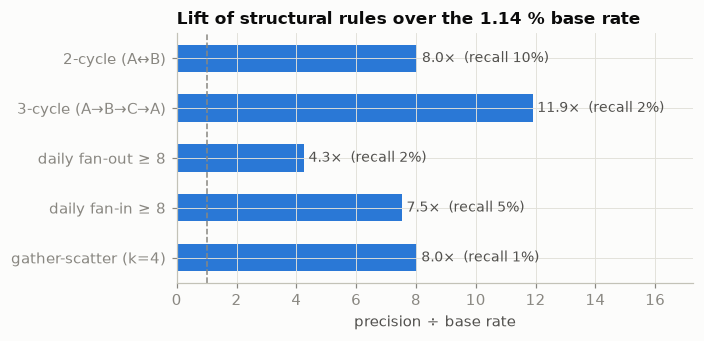

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.barh(lift.index[::-1], lift.lift_vs_base[::-1], color=SERIES[0], height=0.55)
for i, (v, r) in enumerate(zip(lift.lift_vs_base[::-1], lift.recall[::-1])):
    ax.text(v + 0.15, i, f"{v:.1f}×  (recall {r:.0%})", va="center", fontsize=9, color="#52514e")
ax.axvline(1, color=MUTED, lw=1, ls="--"); ax.set_xlim(0, lift.lift_vs_base.max() * 1.45)
ax.set_title("Lift of structural rules over the 1.14 % base rate"); ax.set_xlabel("precision ÷ base rate")
plt.tight_layout()

**Reading this.** Each rule on its own is a weak detector: a 3-cycle lifts precision ~12× but catches under 2 % of laundering accounts; 2-cycles catch ~10 % at ~8×. Real monitoring systems run dozens of such rules and drown analysts in alerts (industry false-positive rates above 90 % are routinely reported). The modelling question is therefore not *"can a rule find laundering?"* but *"can we rank accounts so that the ones at the top of the queue are worth an analyst's time?"*

## 6 · Control experiment: what do transaction rows know on their own?

*Part B · Given model · reference only: the argument for scoring accounts, not a service you deploy.*

Before building the account model, train a gradient-boosted classifier on **transaction rows only** (amount, format, currency, hour, same-bank flag), with a clean temporal split (train days 1–7, test days 8–10). Look at the payment-format table in Section 2 first: 85 % of laundering transfers in this simulator travel by ACH (0.64 % laundering rate against 0.02 % on cheques and cards). A row-level model will find that rail quickly; the question is what is left once it has.

In [12]:
import lightgbm as lgb
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

def tabular_features(d: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=d.index)
    X["log_usd"] = np.log1p(d.amt_usd)
    X["hour"] = d.ts.dt.hour
    X["same_bank"] = (d.from_bank == d.to_bank).astype(int)
    X["is_self"] = d.is_self.astype(int)
    X["cross_currency"] = (d.recv_cur.astype(str) != d.pay_cur.astype(str)).astype(int)
    X["round_amount"] = (d.amt_paid % 100 == 0).astype(int)
    X["fmt"] = d.fmt.astype(str).astype("category")
    X["pay_cur"] = d.pay_cur.astype(str).astype("category")
    return X

def precision_at_k(y_true, score, k):
    top = np.argsort(-np.asarray(score))[:k]
    y = np.asarray(y_true)
    return y[top].mean(), y[top].sum() / y.sum()

train_tx = tx[tx.ts < TRAIN_END]; test_tx = tx[tx.ts >= TRAIN_END]
# keep every positive, sample 10% of negatives in training (speed only; evaluation is on the untouched test days)
neg = train_tx[train_tx.is_laundering == 0].sample(frac=0.10, random_state=SEED)
train_s = pd.concat([train_tx[train_tx.is_laundering == 1], neg]).sort_index()
del train_tx, neg                         # keep only the sampled training rows in memory
print(f"train rows {len(train_s):,} (positives {train_s.is_laundering.sum():,}) · test rows {len(test_tx):,} (positives {test_tx.is_laundering.sum():,})")

t0 = time.time()
clf_tx = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=63, scale_pos_weight=10,
                            subsample=0.8, colsample_bytree=0.8, random_state=SEED, verbose=-1)
clf_tx.fit(tabular_features(train_s), train_s.is_laundering)
p_tx = clf_tx.predict_proba(tabular_features(test_tx))[:, 1]
pk, rk = precision_at_k(test_tx.is_laundering, p_tx, 1000)
print(f"transaction-level tabular model · AUPRC {average_precision_score(test_tx.is_laundering, p_tx):.4f} "
      f"(base rate {test_tx.is_laundering.mean():.4f}) · AUC {roc_auc_score(test_tx.is_laundering, p_tx):.3f} · "
      f"precision@1000 {pk:.3f} · {time.time()-t0:.0f}s")

train rows 375,891 (positives 3,027) · test rows 1,345,565 (positives 1,495)


transaction-level tabular model · AUPRC 0.0680 (base rate 0.0011) · AUC 0.919 · precision@1000 0.155 · 17s


Rows do carry signal (about one in six of the top-1,000 transfers is laundering, at a 0.1 % base rate), and almost all of it is *which rail* plus *how much*. Two problems with building on that: a rail-based rule is trivially evaded (switch from ACH to cheques), and the unit of decision for an analyst is not a transfer. Hence the account model.

## 7 · The account-level triage model

*Part B · Given model · package `fit_eval` and `motif` unchanged and reproduce the numbers (C2).*

The unit of decision is the **account** (an analyst opens a case on a customer, not on a transfer), so the model scores accounts. Two feature families:

- **Profile features**: what a conventional system computes per account: counts, amounts, currencies, formats, active days, cash and crypto shares, in/out flow balance.
- **Structural features**: what only the graph gives you: degrees, PageRank, k-core, cycle membership, fan-in/out peaks, gather-scatter, component size, community size, how hub-like your counterparties are.

We train three models (profile only, structural only, and both) and compare them on **precision at k**, where *k* is the number of accounts the analysts can investigate.

> **Evaluation design (and its limitation).** Accounts are split 70/30 at random, stratified on the label, and every feature is computed on the full 10-day window. This is a *transductive* evaluation: the structure around a test account includes edges to training accounts. It is the standard set-up for node classification and it answers "can the model recognise laundering structure?". ⚠ It does **not** answer "would this have worked last Monday on accounts it had never seen?": Trap 1 measures that.

In [13]:
t0 = time.time()
fmt_str = tx.fmt.astype(str)
flags = tx[["ts", "from_acct", "amt_usd", "pay_cur", "fmt", "to_bank", "day", "is_self", "amt_paid"]].assign(  # columns used below
    is_cash=(fmt_str == "Cash"), is_crypto=(fmt_str == "Bitcoin"), is_wire=(fmt_str == "Wire"),
    is_round=(tx.amt_paid % 100 == 0))
# ---- profile features (sender side, receiver side, activity) ----
out_ = flags.groupby("from_acct", observed=True).agg(
    n_out=("ts", "size"), usd_out=("amt_usd", "sum"), usd_out_mean=("amt_usd", "mean"), usd_out_max=("amt_usd", "max"),
    n_cur_out=("pay_cur", "nunique"), n_fmt_out=("fmt", "nunique"), n_banks_out=("to_bank", "nunique"),
    active_days=("day", "nunique"), cash_share=("is_cash", "mean"), crypto_share=("is_crypto", "mean"),
    wire_share=("is_wire", "mean"), round_share=("is_round", "mean"), self_share=("is_self", "mean"))
in_ = tx.groupby("to_acct", observed=True).agg(
    n_in=("ts", "size"), usd_in=("amt_usd", "sum"), usd_in_mean=("amt_usd", "mean"), n_banks_in=("from_bank", "nunique"))
prof = out_.join(in_, how="outer").fillna(0)
prof["flow_ratio"] = np.log1p(prof.usd_out) - np.log1p(prof.usd_in)
prof["pass_through"] = np.minimum(prof.usd_in, prof.usd_out) / (np.maximum(prof.usd_in, prof.usd_out) + 1)

# ---- structural features ----
st = struct.drop(columns=["is_laundering_acct"]).copy()
st["in_deg"] = pd.Series(dict(G.in_degree())); st["out_deg"] = pd.Series(dict(G.out_degree()))
st["pagerank"] = pd.Series(nx.pagerank(G, weight="usd"))
Gu = G.to_undirected()
st["core"] = pd.Series(nx.core_number(Gu))
comp = {n: i for i, c in enumerate(nx.weakly_connected_components(G)) for n in c}
comp_size = pd.Series(comp).map(pd.Series(comp).value_counts())
st["log_component_size"] = np.log10(comp_size)
if RUN_LOUVAIN:
    t1 = time.time()
    comms = nx.community.louvain_communities(Gu, seed=SEED)
    cid = {n: i for i, c in enumerate(comms) for n in c}
    st["log_community_size"] = np.log10(pd.Series(cid).map(pd.Series(cid).value_counts()))
    print(f"louvain: {len(comms):,} communities in {time.time()-t1:.0f}s")
# neighbour aggregates: how 'hub-like' are the accounts you send to?
nbr_out_deg = pd.Series({n: np.mean([G.in_degree(m) for m in G.successors(n)]) if G.out_degree(n) else 0 for n in nodes})
st["nbr_mean_in_deg"] = nbr_out_deg

acct = prof.join(st, how="left").fillna(0)
acct["y"] = acct.index.isin(laundering_accounts).astype(int)
PROFILE = list(prof.columns)
STRUCT = [c for c in st.columns]
print(f"{len(acct):,} accounts · {len(PROFILE)} profile + {len(STRUCT)} structural features · {time.time()-t0:.0f}s")

louvain: 23,638 communities in 136s


515,070 accounts · 19 profile + 12 structural features · 170s


In [14]:
from sklearn.model_selection import train_test_split

idx_tr, idx_te = train_test_split(np.arange(len(acct)), test_size=0.3, random_state=SEED, stratify=acct.y)
y_tr, y_te = acct.y.values[idx_tr], acct.y.values[idx_te]

KS = [100, 200, 500, 1000, 2000, 3000]

def fit_eval(cols, name):
    t1 = time.time()
    m = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.03, num_leaves=63, min_child_samples=40,
                           scale_pos_weight=20, subsample=0.8, colsample_bytree=0.8, random_state=SEED, verbose=-1)
    m.fit(acct.iloc[idx_tr][cols], y_tr)
    p = m.predict_proba(acct.iloc[idx_te][cols])[:, 1]
    res = {"model": name, "AUPRC": average_precision_score(y_te, p), "AUC": roc_auc_score(y_te, p)}
    res.update({f"p@{k}": precision_at_k(y_te, p, k)[0] for k in KS})
    res["fit_s"] = time.time() - t1
    return m, p, res

m_prof, p_prof, r_prof = fit_eval(PROFILE, "profile only")
m_str, p_str, r_str = fit_eval(STRUCT, "structural only")
m_all, p_all, r_all = fit_eval(PROFILE + STRUCT, "profile + structural")
results = pd.DataFrame([r_prof, r_str, r_all]).set_index("model")
print(f"held-out accounts: {len(y_te):,} · laundering among them: {y_te.sum():,}")
results.style.format({"AUPRC": "{:.3f}", "AUC": "{:.3f}", "fit_s": "{:.0f}", **{f"p@{k}": "{:.0%}" for k in KS}})

held-out accounts: 154,521 · laundering among them: 1,759


,AUPRC,AUC,p@100,p@200,p@500,p@1000,p@2000,p@3000,fit_s
model,,,,,,,,,
profile only,0.265,0.885,100%,98%,64%,38%,24%,19%,14
structural only,0.100,0.843,48%,41%,27%,19%,14%,12%,12
profile + structural,0.292,0.909,100%,99%,67%,40%,25%,20%,16


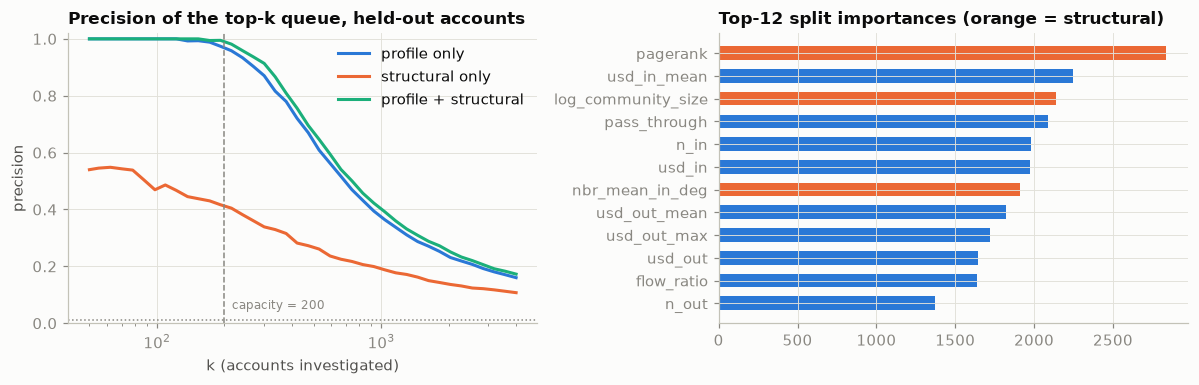

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ks = np.unique(np.geomspace(50, 4000, 40).astype(int))
for p, lab, color in [(p_prof, "profile only", SERIES[0]), (p_str, "structural only", SERIES[1]),
                      (p_all, "profile + structural", SERIES[2])]:
    ax.plot(ks, [precision_at_k(y_te, p, k)[0] for k in ks], lw=2, color=color, label=lab)
ax.axvline(ANALYST_CAPACITY, color=MUTED, ls="--", lw=1)
ax.text(ANALYST_CAPACITY * 1.08, 0.05, f"capacity = {ANALYST_CAPACITY}", color=MUTED, fontsize=8)
ax.axhline(base_rate, color=MUTED, ls=":", lw=1)
ax.set_xscale("log"); ax.set_ylim(0, 1.02)
ax.set_title("Precision of the top-k queue, held-out accounts"); ax.set_xlabel("k (accounts investigated)"); ax.set_ylabel("precision")
ax.legend(loc="upper right")

ax = axes[1]
imp = pd.Series(m_all.feature_importances_, index=PROFILE + STRUCT).sort_values(ascending=False).head(12)
colors = [SERIES[1] if f in STRUCT else SERIES[0] for f in imp.index]
ax.barh(imp.index[::-1], imp.values[::-1], color=colors[::-1], height=0.6)
ax.set_title("Top-12 split importances (orange = structural)")
plt.tight_layout()

In [16]:
# What does the analyst get on Monday morning? The top-200 queue, with the motif that explains each entry.
queue = acct.iloc[idx_te][["y", "two_cycle", "three_cycle", "max_fan_out_day", "max_fan_in_day", "gather_scatter",
                           "in_deg", "out_deg", "usd_in", "usd_out"]].copy()
queue["score"] = p_all
queue = queue.sort_values("score", ascending=False).head(ANALYST_CAPACITY)

def motif(r):
    tags = []
    if r.three_cycle > 0: tags.append("3-cycle")
    if r.two_cycle > 0: tags.append("2-cycle")
    if r.gather_scatter: tags.append("gather-scatter")
    if r.max_fan_out_day >= 8: tags.append(f"fan-out {int(r.max_fan_out_day)}/day")
    if r.max_fan_in_day >= 8: tags.append(f"fan-in {int(r.max_fan_in_day)}/day")
    return ", ".join(tags) or "no simple motif (model-only)"
queue["why"] = queue.apply(motif, axis=1)
print(f"top-{ANALYST_CAPACITY}: {queue.y.sum()} true laundering accounts ({queue.y.mean():.0%}); "
      f"{(queue.why == 'no simple motif (model-only)').mean():.0%} of flags have no single-rule explanation")
queue.head(10)[["score", "y", "why", "in_deg", "out_deg", "usd_in", "usd_out"]].style.format(
    {"score": "{:.3f}", "usd_in": "{:,.0f}", "usd_out": "{:,.0f}"})

top-200: 198 true laundering accounts (99%); 92% of flags have no single-rule explanation


,score,y,why,in_deg,out_deg,usd_in,usd_out
from_acct,,,,,,,
80515A830,0.999,1,no simple motif (model-only),1.000000,1.000000,"63,932","77,238"
80BEF6450,0.999,1,no simple motif (model-only),0.000000,1.000000,"20,674","23,647"
8078D10C0,0.998,1,no simple motif (model-only),2.000000,1.000000,"39,248","40,782"
80D9A31F0,0.998,1,no simple motif (model-only),0.000000,1.000000,"13,998","17,857"
80B89ED40,0.998,1,no simple motif (model-only),0.000000,1.000000,"6,968","12,200"
80D45D750,0.998,1,no simple motif (model-only),0.000000,1.000000,"28,717","35,727"
80FCC1740,0.998,1,no simple motif (model-only),3.000000,1.000000,"61,726","27,871"
809B70360,0.998,1,no simple motif (model-only),0.000000,1.000000,"11,308","21,426"
801C0F2B0,0.998,1,no simple motif (model-only),1.000000,4.000000,"30,469","37,859"


## 8 · Reading the result — when does the graph earn its cost?

*Part B · Given model · read; your stakeholder recommendation starts here.*

Be honest about what the table says, because a stakeholder will be:

1. **The top of the queue is easy, for any model.** At k = 100–200 both profile-based models are near-perfect: a few hundred accounts move very large sums through the simulator's laundering patterns and nothing subtle is needed to find them. Precision at the analysts' capacity therefore *saturates* and tells you little about model quality. Look further down the curve (k = 1,000–3,000), where the queue is a mix of real and spurious flags: that is where the operational pain lives, and where the three models separate.
2. **Amounts dominate; structure adds a few points, here.** The profile model leans on in/out amounts and flow balance; adding structure lifts AUPRC by a few points and lifts precision mostly in the 500–3,000 band. The structural-only model, with *no* amount information at all, still reaches a respectable AUC: structure is a genuinely independent signal. Whether it is *worth its cost* is the question the task asks you to settle; note that in a real bank, launderers structure amounts to stay unremarkable, which removes much of the profile signal this simulator hands you.
3. **The explanation gap.** Most top-ranked accounts match no single motif rule: the model is combining weak signals. An analyst needs *some* narrative for those cases, which is the hand-over to Session 10 (generate the case note from the ego-network) and Session 07 (the entity graph as a knowledge graph).
4. **Cost of running it.** Node features on ~420 k accounts cost tens of seconds; Louvain a couple of minutes; a GNN would cost GPU time. Against a few hundred investigations a week, put a number on it in your recommendation (Session 11's cost thread).

Before you package it, Section 9 measures four ways this baseline can mislead.

## 9 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Four shortcuts, each making a number look better, or an assumption look safer, than the system is. Each is measured against the given model (AUPRC 0.292, 198 of 200 at capacity).

**Trap 1 — the transductive split.** Section 7 splits accounts at random and computes every feature on all ten days, so the model learns from the same days, and often the same laundering attempts, that it is tested on. A bank learns on last week and scores this week. The forward version learns on the accounts of days 1–5 (`FORWARD_SPLIT`) and scores the accounts of days 6–10 from their days 6–10 activity alone. Both sides use Section 7's features without Louvain's community size, since two more Louvain runs would add over four minutes; dropping it costs the transductive model 0.003 AUPRC. The forward week ranks 2.4 times as many accounts as the held-out 30 %, so compare the lift (AUPRC ÷ base rate), not precision at a fixed k.

In [17]:
# Trap 1: the transductive split against a forward evaluation in time
del flags, Gu, A, G, fan_out_day, fan_in_day, fi, fo, fo_next, comms, cid, comp, comp_size, nbr_out_deg, fmt_str, train_s
import gc; gc.collect()                       # free memory: Sections 5-7's working copies are no longer needed
t0 = time.time()
FWD_COLS = [c for c in PROFILE + STRUCT if c != "log_community_size"]   # Louvain left out on both sides (runtime)

def profile_table(d: pd.DataFrame) -> pd.DataFrame:
    '''Section 7's profile features on a slice of transactions.'''
    fs = d.fmt.astype(str)
    f = d[["ts", "from_acct", "amt_usd", "pay_cur", "fmt", "to_bank", "day", "is_self", "amt_paid"]].assign(is_cash=(fs == "Cash"), is_crypto=(fs == "Bitcoin"), is_wire=(fs == "Wire"), is_round=(d.amt_paid % 100 == 0))
    o = f.groupby("from_acct", observed=True).agg(
        n_out=("ts", "size"), usd_out=("amt_usd", "sum"), usd_out_mean=("amt_usd", "mean"), usd_out_max=("amt_usd", "max"),
        n_cur_out=("pay_cur", "nunique"), n_fmt_out=("fmt", "nunique"), n_banks_out=("to_bank", "nunique"),
        active_days=("day", "nunique"), cash_share=("is_cash", "mean"), crypto_share=("is_crypto", "mean"),
        wire_share=("is_wire", "mean"), round_share=("is_round", "mean"), self_share=("is_self", "mean"))
    del f
    i = d.groupby("to_acct", observed=True).agg(
        n_in=("ts", "size"), usd_in=("amt_usd", "sum"), usd_in_mean=("amt_usd", "mean"), n_banks_in=("from_bank", "nunique"))
    pr = o.join(i, how="outer").fillna(0)
    pr["flow_ratio"] = np.log1p(pr.usd_out) - np.log1p(pr.usd_in)
    pr["pass_through"] = np.minimum(pr.usd_in, pr.usd_out) / (np.maximum(pr.usd_in, pr.usd_out) + 1)
    return pr

def account_table(d: pd.DataFrame) -> pd.DataFrame:
    '''Section 7's profile and structural features on a slice of transactions (no Louvain); label from the same slice.'''
    pr = profile_table(d)
    ns = d[~d.is_self]
    e = ns.groupby(["from_acct", "to_acct"], observed=True).agg(n_tx=("ts", "size"), usd=("amt_usd", "sum")).reset_index()
    g = nx.DiGraph()
    g.add_edges_from(((r.from_acct, r.to_acct, {"usd": r.usd}) for r in e.itertuples(index=False)))
    nl = list(g.nodes())
    a = nx.to_scipy_sparse_array(g, nodelist=nl, format="csr", weight=None)
    s = pd.DataFrame({"two_cycle": np.asarray(a.multiply(a.T).sum(axis=1)).ravel(),
                      "three_cycle": np.asarray((a @ a).multiply(a.T).sum(axis=1)).ravel()}, index=nl)
    fo_d = ns.groupby(["from_acct", "day"], observed=True).to_acct.nunique()
    fi_d = ns.groupby(["to_acct", "day"], observed=True).from_acct.nunique()
    s["max_fan_out_day"] = fo_d.groupby(level=0).max().reindex(nl).fillna(0).values
    s["max_fan_in_day"] = fi_d.groupby(level=0).max().reindex(nl).fillna(0).values
    fi_ = fi_d[fi_d >= 4].reset_index(); fo_ = fo_d[fo_d >= 4].reset_index()   # k = 4, as in Section 5
    fi_.columns = ["acct", "day", "fi"]; fo_.columns = ["acct", "day", "fo"]
    gs_ = pd.concat([fi_.merge(fo_, on=["acct", "day"]),
                     fi_.merge(fo_.assign(day=fo_.day - pd.Timedelta(days=1)), on=["acct", "day"])]).acct.unique()
    s["gather_scatter"] = s.index.isin(gs_).astype(int)
    s["in_deg"] = pd.Series(dict(g.in_degree())); s["out_deg"] = pd.Series(dict(g.out_degree()))
    s["pagerank"] = pd.Series(nx.pagerank(g, weight="usd"))
    s["core"] = pd.Series(nx.core_number(g.to_undirected()))
    cm = {n: j for j, c in enumerate(nx.weakly_connected_components(g)) for n in c}
    s["log_component_size"] = np.log10(pd.Series(cm).map(pd.Series(cm).value_counts()))
    s["nbr_mean_in_deg"] = pd.Series({n: np.mean([g.in_degree(m) for m in g.successors(n)]) if g.out_degree(n) else 0 for n in nl})
    t = pr.join(s, how="left").fillna(0)
    bad = set(d.loc[d.is_laundering == 1, "from_acct"]) | set(d.loc[d.is_laundering == 1, "to_acct"])
    t["y"] = t.index.isin(bad).astype(int)
    return t

def fit_score(X_tr, y_tr_, X_te):
    '''The given model's learner and settings (as in fit_eval), on any train/test pair.'''
    m = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.03, num_leaves=63, min_child_samples=40,
                           scale_pos_weight=20, subsample=0.8, colsample_bytree=0.8, random_state=SEED, verbose=-1)
    m.fit(X_tr, y_tr_)
    return m.predict_proba(X_te)[:, 1]

def summary(y, p, name):
    return {"evaluation": name, "accounts": len(y), "laundering": int(np.sum(y)), "base rate": np.mean(y),
            "AUPRC": average_precision_score(y, p), "lift": average_precision_score(y, p) / np.mean(y),
            "p@200": precision_at_k(y, p, ANALYST_CAPACITY)[0], "p@1000": precision_at_k(y, p, 1000)[0]}

# naive: the transductive split of Section 7, same features as the forward run (no community size)
_, p_naive, _ = fit_eval(FWD_COLS, "transductive, no community size")
# honest: learn on the accounts of days 1-5, score the accounts of days 6-10 from their days 6-10 activity
tr_tab = account_table(tx[tx.ts < FORWARD_SPLIT])
te_tab = account_table(tx[tx.ts >= FORWARD_SPLIT])
p_fwd = fit_score(tr_tab[FWD_COLS], tr_tab.y, te_tab[FWD_COLS])
seen = te_tab.index.isin(tr_tab.index)
trap1 = pd.DataFrame([summary(y_te, p_all, "transductive (headline, Section 7)"),
                      summary(y_te, p_naive, "transductive, no community size"),
                      summary(te_tab.y.values, p_fwd, "forward: train days 1-5, test days 6-10"),
                      summary(te_tab.y.values[~seen], p_fwd[~seen], "forward, accounts new in days 6-10")]).set_index("evaluation")
print(f"train window: {len(tr_tab):,} accounts ({tr_tab.y.sum():,} laundering) · test window: {len(te_tab):,} accounts "
      f"({te_tab.y.sum():,} laundering, {(~seen).sum():,} new) · {time.time()-t0:.0f}s")
trap1.style.format({"accounts": "{:,}", "laundering": "{:,}", "base rate": "{:.2%}", "AUPRC": "{:.3f}",
                    "lift": "{:.1f}×", "p@200": "{:.0%}", "p@1000": "{:.0%}"})

train window: 512,304 accounts (2,799 laundering) · test window: 372,954 accounts (3,357 laundering, 2,766 new) · 115s


,accounts,laundering,base rate,AUPRC,lift,p@200,p@1000
evaluation,,,,,,,
"transductive (headline, Section 7)","154,521","1,759",1.14%,0.292,25.7×,99%,40%
"transductive, no community size","154,521","1,759",1.14%,0.289,25.4×,98%,40%
"forward: train days 1-5, test days 6-10","372,954","3,357",0.90%,0.247,27.5×,100%,62%
"forward, accounts new in days 6-10","2,766",76,2.75%,0.237,8.6×,17%,6%


Forward in time, the model holds on the accounts it already knew: AUPRC falls from 0.289 to 0.247, but on a lower base rate (0.90 % against 1.14 %), so the lift is 27.5× against 25.4× and the top 200 are all laundering. It does not hold on the 2,766 accounts first seen in days 6–10: their lift falls to 8.6×, and their top 200 hold 34 of their 76 launderers among 166 false alerts. New accounts are where fresh mules appear, so the model card carries the new-account number next to the headline, and C1 makes the forward evaluation the pipeline's reported number.

**Trap 2 — the fixed FX table.** Every amount feature is the payment amount times a rate we typed in (`FX`, quirk 4). Rebuild the profile features with no conversion at all, and with every rate moved by up to ±25 %, and retrain.

In [18]:
# Trap 2: the fixed FX table. Recompute the profile (amount) features under other tables; graph features unchanged.
t0 = time.time()
usd_table = tx.amt_usd.copy()
rng = np.random.default_rng(SEED)
FX_JITTER = {c: r * float(rng.uniform(0.8, 1.25)) for c, r in FX.items()}   # every rate moved by up to ±25 %
variants = {"no conversion (payment-currency units)": tx.amt_paid.values,
            "every rate moved by up to ±25 %": (tx.amt_paid * tx.pay_cur.astype(str).map(FX_JITTER)).values}
fx_rows = [summary(y_te, p_all, "fixed FX table (headline)")]
top_head = set(acct.index[idx_te][np.argsort(-p_all)[:ANALYST_CAPACITY]])
overlap = {"fixed FX table (headline)": 1.0}
for name, amounts in variants.items():
    tx["amt_usd"] = amounts
    alt = acct.copy()
    alt[PROFILE] = profile_table(tx).reindex(acct.index).fillna(0)[PROFILE]   # structure (incl. USD-weighted PageRank) as in Section 7
    p_alt = fit_score(alt.iloc[idx_tr][PROFILE + STRUCT], y_tr, alt.iloc[idx_te][PROFILE + STRUCT])
    fx_rows.append(summary(y_te, p_alt, name))
    overlap[name] = len(top_head & set(acct.index[idx_te][np.argsort(-p_alt)[:ANALYST_CAPACITY]])) / ANALYST_CAPACITY
tx["amt_usd"] = usd_table; del usd_table, alt
trap2 = pd.DataFrame(fx_rows).set_index("evaluation").drop(columns=["accounts", "laundering", "base rate"])
trap2["same top-200 as headline"] = pd.Series(overlap)
print(f"FX variants rebuilt in {time.time()-t0:.0f}s")
trap2.style.format({"AUPRC": "{:.3f}", "lift": "{:.1f}×", "p@200": "{:.0%}", "p@1000": "{:.0%}",
                    "same top-200 as headline": "{:.0%}"})

FX variants rebuilt in 42s


,AUPRC,lift,p@200,p@1000,same top-200 as headline
evaluation,,,,,
fixed FX table (headline),0.292,25.7×,99%,40%,100%
no conversion (payment-currency units),0.292,25.7×,99%,40%,91%
every rate moved by up to ±25 %,0.291,25.5×,98%,40%,94%


The headline does not move: AUPRC 0.292 with no conversion and 0.291 with the moved rates, precision at capacity 98–99 %. That is the trap: a metric that cannot see an assumption invites the conclusion that the assumption is harmless. The queue does see it: 18 of the top 200 accounts change with no conversion and 12 with the moved rates (different launderers, still launderers), and every amount an analyst reads in a case comes from the table. Trees use only the order of values, and any rate keeps the order within a currency; the table matters where currencies are summed together. C1 pins the table's version and source with a test, and E1's analyst view shows the payment-currency amount next to the converted one.

**Trap 3 — the laundering-only tail.** Normal traffic stops on 10 September; days 11–18 hold 1,108 transfers, 59 % of them laundering (quirk 1). Keep them in Section 6's test days and score them with the same row model.

In [19]:
# Trap 3: the laundering-only tail. Score days 11-18 with Section 6's row model and add them to its test days.
tail = pd.read_parquet(PROCESSED / "aml_hi_small.parquet", filters=[("ts", ">=", WINDOW_END)])   # Section 1's cache, tail only
tail["amt_usd"] = tail.amt_paid * tail.pay_cur.astype(str).map(FX)
tail["is_self"] = tail.from_acct == tail.to_acct
p_tail = clf_tx.predict_proba(tabular_features(tail))[:, 1]
y_rows = np.r_[test_tx.is_laundering.values, tail.is_laundering.values]
p_rows = np.r_[p_tx, p_tail]
trap3 = pd.DataFrame([
    {"evaluation": "test days 8-10 (Section 6)", "rows": len(test_tx), "laundering": int(test_tx.is_laundering.sum()),
     "AUPRC": average_precision_score(test_tx.is_laundering, p_tx), "p@1000": precision_at_k(test_tx.is_laundering, p_tx, 1000)[0]},
    {"evaluation": "test days 8-18, tail kept", "rows": len(y_rows), "laundering": int(y_rows.sum()),
     "AUPRC": average_precision_score(y_rows, p_rows), "p@1000": precision_at_k(y_rows, p_rows, 1000)[0]}]).set_index("evaluation")
top_rows = np.argsort(-p_rows)[:1000]
tail_accts = (set(tail.from_acct) | set(tail.to_acct)) - set(acct.index)
tail_bad = set(tail.loc[tail.is_laundering == 1, "from_acct"]) | set(tail.loc[tail.is_laundering == 1, "to_acct"])
print(f"tail: {len(tail):,} rows, {tail.is_laundering.mean():.0%} laundering · {(top_rows >= len(test_tx)).sum()} of the top 1,000 "
      f"come from the tail · {len(tail_accts):,} accounts appear only in the tail, {len(tail_accts & tail_bad) / len(tail_accts):.0%} of them laundering")
trap3.style.format({"rows": "{:,}", "laundering": "{:,}", "AUPRC": "{:.4f}", "p@1000": "{:.1%}"})

tail: 1,108 rows, 59% laundering · 93 of the top 1,000 come from the tail · 10 accounts appear only in the tail, 100% of them laundering


,rows,laundering,AUPRC,p@1000
evaluation,,,,
test days 8-10 (Section 6),"1,345,565","1,495",0.0680,15.5%
"test days 8-18, tail kept","1,346,673","2,150",0.1146,23.4%


Without any change to the model, AUPRC rises from 0.0680 to 0.1146 and precision in the top 1,000 transfers from 15.5 % to 23.4 %; 93 of the top 1,000 are tail rows. At account level the tail adds 10 accounts that appear nowhere else, all of them laundering. A `WINDOW_END` set past 10 September would pass any gate, so C1 asks for a test that fails when the window reaches the tail.

**Trap 4 — self-transfers as edges.** 11.6 % of rows pay the sender's own account (quirk 3). Section 4 keeps them out of the graph; a repackaged pipeline that builds the adjacency straight from the table puts them back as self-loops, and in Section 5's sparse formulas a self-loop counts as both a 2-cycle and a 3-cycle.

In [20]:
# Trap 4: self-transfers as graph edges. Section 4 drops them; here they go back in as self-loops.
pos = pd.Series(np.arange(len(nodes)), index=nodes)
loops = pd.Index(tx.loc[tx.is_self, "from_acct"].unique())
extra = loops.difference(pos.index)                       # accounts that only ever pay themselves: not in G
pos = pd.concat([pos, pd.Series(np.arange(len(nodes), len(nodes) + len(extra)), index=extra)])
n_all = len(pos)
r, c = pos[edges.from_acct].values, pos[edges.to_acct].values
A_ok = sp.csr_matrix((np.ones(len(r)), (r, c)), shape=(n_all, n_all))
A_loop = A_ok + sp.csr_matrix((np.ones(len(loops)), (pos[loops].values, pos[loops].values)), shape=(n_all, n_all))
y_all = pos.index.isin(laundering_accounts)
rows4 = []
for name, M in [("Section 4: no self-loops", A_ok), ("self-transfers as edges", A_loop)]:
    for rule, cnt in [("2-cycle", M.multiply(M.T).sum(axis=1)), ("3-cycle", (M @ M).multiply(M.T).sum(axis=1))]:
        hit = np.asarray(cnt).ravel() > 0
        rows4.append({"graph": name, "rule": rule, "accounts_flagged": int(hit.sum()), "precision": y_all[hit].mean(),
                      "recall": y_all[hit].sum() / len(laundering_accounts), "lift_vs_base": y_all[hit].mean() / base_rate})
print(f"{len(loops):,} accounts pay themselves ({len(extra):,} of them never pay anyone else)")
pd.DataFrame(rows4).set_index(["graph", "rule"]).style.format(
    {"accounts_flagged": "{:,}", "precision": "{:.1%}", "recall": "{:.1%}", "lift_vs_base": "{:.1f}×"})

367,753 accounts pay themselves (92,422 of them never pay anyone else)


With self-loops, the 2-cycle rule flags 368,771 accounts instead of 6,680 and its lift falls from 8.0× to 1.3×; the 3-cycle rule falls from 11.9× to 1.2×. 367,753 accounts pay themselves, 92,422 of them never anyone else, so 72 % of all accounts become "cycles". Recall rises to 89.6 % only because most laundering accounts pay themselves too. The motif tags in the analyst's queue (Section 7) would name a cycle for almost everyone, so C1 asks for a test: a hand-built account that pays itself is not a cycle.

# Part C — Productionise it

*Sections 10–12: this is your assignment.*

## 10 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The ten principles every project covers, updated with what this notebook measured.

In [21]:
import hashlib
holdout = acct.iloc[idx_te][["y"]].reset_index()
holdout_fp = hashlib.sha256(pd.util.hash_pandas_object(holdout, index=False).values.tobytes()).hexdigest()
print(f"frozen evaluation split: {len(holdout):,} accounts, {holdout.y.sum():,} laundering · SHA-256 {holdout_fp[:16]}…")
print(f"headline: AUPRC {r_all['AUPRC']:.3f} · p@{ANALYST_CAPACITY} {queue.y.mean():.1%} · "
      f"p@1000 {r_all['p@1000']:.1%} · p@3000 {r_all['p@3000']:.1%} · forward p@200 {trap1.loc['forward: train days 1-5, test days 6-10', 'p@200']:.1%}")

frozen evaluation split: 154,521 accounts, 1,759 laundering · SHA-256 d4d1fbf90a2856e4…
headline: AUPRC 0.292 · p@200 99.0% · p@1000 40.1% · p@3000 20.1% · forward p@200 100.0%


| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/aml_triage/` (`load.py`: `get_raw`, `load_transactions`, the `FX` table; `graph.py`: the edge list without self-loops and the structural signals; `features.py`, `train.py`: `fit_eval`, `motif`); a nightly batch container that writes the top-200 queue to Postgres |
| Monitoring (S04) | Queue precision once analysts close cases (99 % at 200, 40 % at 1,000 today); the share of the queue with no single-motif explanation (92 %); transfers a day against the 208 k–654 k of days 8–10 (a day of 396, as on 11 September, means the feed has changed); the `FX` table's version |
| CI/CD gate (S05) | The frozen split (154,521 accounts, 1,759 laundering, SHA-256 `d4d1fbf90a2856e4…`): precision at 200 is 99 % but saturates, so gate also on precision at 1,000 (40.1 %) and on the forward AUPRC (0.247); tests for the window (no tail), self-loops, the `FX` version and a hand-built 4-node cycle |
| MLflow tracking and registry (S06) | `WINDOW_START`, `WINDOW_END`, `FORWARD_SPLIT`, `SEED`, a hash of the `FX` table; the three feature-family runs (AUPRC 0.265, 0.100, 0.292); transductive and forward numbers side by side; a `champion` alias |
| Offline / online training and serving | Offline only: nightly batch scoring, weekly retraining, a queue read in the morning. The account features take about 165 s on 5.08 M transfers, about 135 s of it Louvain |
| Data and model drift | Forward in time the lift holds for known accounts (27.5×) and falls to 8.6× for accounts new in the scoring window; the day-1 burst (1.1 M transfers) inflates the reference window's degrees; the laundering-only regime from 11 September |
| Knowledge base and context (S07–S09) | The account graph: 422,648 nodes, 647,316 edges, 21,817 weakly connected components (the largest holds 88 %); `HI-Small_accounts.csv` lifts it to entities and banks. Ablation AUPRC: profile 0.265, structure 0.100, both 0.292 |
| GenAI and context engineering (S10–S11) | Investigator note from a top-20 account's 2-hop ego-network only; golden set from the 234 typed attempts in `HI-Small_Patterns.txt`; 92 % of the queue matches no single motif, so the note must cite edges, not rules |
| Governance | Synthetic, CDLA-Sharing-1.0 (derived data carries the same licence); no personal data; the EU AI Act classification put to compliance as questions (E4); the model card names the tail, the `FX` assumption and the transductive-against-forward gap |

## 11 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S2**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap, with a test.** The forward evaluation of Trap 1 as the reported number, with a test that fails if a scored account's features use days after `FORWARD_SPLIT`, and the new-account lift beside it; a test that pins the `FX` table's version and source and reports the top-200 overlap when the table changes; a window test that fails when `WINDOW_END` reaches the laundering-only tail; a motif test that fails if a self-transfer becomes an edge (a hand-built account paying itself is not a cycle). *Decide and document*: is the weekly batch window the right one for this bank?
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Set the operating point from capacity, not from a threshold.** The team can investigate `ANALYST_CAPACITY` accounts per cycle. Show how precision and recall move if capacity halves or doubles, and write the one-paragraph recommendation to the Head of Compliance.
- **C4 — Package and gate.** Move feature construction and training into `src/`, add tests for the motif functions (a hand-built 4-node cycle must be detected), and add a CI quality gate on precision@200 against the frozen evaluation split and its fingerprint (Section 10; Session 05).
- **C5 — Register and document.** Track runs in MLflow, register the chosen model with a `champion` alias, and attach a model card that names the synthetic provenance, the tail artefact, the FX assumption and the transductive-vs-temporal gap (Session 06).

### Extension

- **E1 — Explain the queue to an analyst.** For the top-20 accounts, show which of the given model's features put each one in the queue (feature contributions, for example SHAP) and which typed attempt it belongs to, if any. Write the one-page analyst view and state what the model cannot see, including the fixed `FX` table it relies on.
- **E2 — A nightly batch job.** Turn scoring into a nightly job: read the day's file, update the graph and features, score, and write the queue to Postgres idempotently (re-running a day must not duplicate cases). Time each stage and state which one limits the overnight window.
- **E3 — Monitoring plan.** The bank receives a new day of data every night. Which features drift when the simulator's day-1 burst is excluded? Specify the PSI reference window, thresholds and the retraining trigger (Session 04), and the rollback path through the registry alias.
- **E4 — Governance.** Classify this system under the EU AI Act (AML monitoring is a deployer-side risk question; note the financial-fraud carve-outs in Annex III and the obligations that still apply), and state what human oversight means for a top-200 queue.

### Stretch

- **S1 — Shadow deployment.** Run the registered model in shadow on the next window beside the current rules, log both queues, and report their overlap, what each alone catches, and the analyst hours a switch would save or cost.
- **S2 — Narratives for analysts.** For each of the top-20 accounts, extract the 2-hop ego-network and generate a short investigator note with an LLM grounded on that subgraph only (Session 10). Evaluate factuality against the typed attempts (Session 11).
- **S3 — Entity-level knowledge graph.** Use `HI-Small_accounts.csv` to lift the graph from accounts to entities and banks, model it as an ontology (Session 08), and show one question that is only answerable at entity level.

## 12 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` not committed
- [ ] `README.md` states the sampling rule (`WINDOW_START`, `WINDOW_END`) and how to obtain the data (Kaggle, CDLA-Sharing-1.0)
- [ ] A failing test for each trap in Section 9 (C1); the forward evaluation reported next to the transductive one, with the new-account lift
- [ ] CI pipeline with tests and the precision@k gate; registered model with model card
- [ ] ADRs for: window choice, FX handling, operating point, feature family choice
- [ ] One-page stakeholder recommendation (what to deploy, what it costs, what it does not catch)
- [ ] Required tasks done: C1–C5, E1–E4 and S2
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `networkx`, `scipy`, `scikit-learn`, `lightgbm`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`).
- Altman, E., Blanuša, J., von Niederhäusern, L., Egressy, B., Anghel, A., Atasu, K. (2023). *Realistic Synthetic Financial Transactions for Anti-Money Laundering Models.* NeurIPS 2023 Datasets and Benchmarks.
- Egressy, B. et al. (2024). *Provably Powerful Graph Neural Networks for Directed Multigraphs.* AAAI 2024 (the Multi-GNN baselines on this data).
- Huyen, C. (2022). *Designing Machine Learning Systems*, Ch. 5 (feature engineering) and Ch. 8 (data distribution shifts and monitoring).

In [22]:
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s" if "T_START" in globals() else "done")

notebook finished · total wall time 429s
